#Task 1: project review
Project title:

**Predicting Customer Churn in a Telecommunications Company Using Customer Account, Service and Billing Information**

##Problem statement:

Telecommunication companies operate on subscription services where customers are free to cancel at any time. A major problem facing these companies is customer churn, where existing customers discontinue their services and move to competing providers. Churn directly reduces revenue, and acquiring a new customer is generally more expensive than retaining an existing one. At present, the retention and marketing team only becomes aware of churn after a customer has already left, and has no reliable way of ranking thousands of active customers by their risk of leaving. Retention offers are therefore given late, or given to customers who were never going to leave. A machine learning model that predicts churn from customer account, service and billing information would allow the retention team to identify high-risk customers in advance and target retention efforts more effectively.

##General objective:

To develop a machine learning model that predicts customer churn in a telecommunications company using customer demographic, service and billing information.

##Specific objectives:

To examine and understand the structure, variables and quality of the Telco customer churn dataset.

To clean and prepare the dataset for machine learning modelling.

To build and evaluate a classification model that predicts whether a customer will churn.

##Expected outcome:

A trained classification model that labels each customer as likely to churn or not, together with the customer characteristics most strongly associated with churn, to support the retention team's targeting decisions.


**The dataset is relevant because it contains 7,043 individual customer records, each with a Churn column indicating whether that customer left, which is exactly the outcome the project aims to predict, and it also contains the account, service and billing variables needed as predictors.**

#Task 2: describing the dataset
Dataset name: Telco Customer Churn (IBM sample dataset)

Source: published by IBM,  distributed on Kaggle.

Link: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

Year/period: not specified in the dataset

File: WA_Fn-UseC_-Telco-Customer-Churn.csv

Observations and variables: 7,043 rows × 21 columns

Unit of analysis: one row = one customer


It contains 7,043 records and 21 variables describing customers of a telecommunications company. Each row represents one customer and includes demographic information (gender, senior citizen status, partner, dependents), the services subscribed to (phone, multiple lines, internet, online security, backup, device protection, technical support, streaming TV and movies), account information (tenure, contract type, paperless billing, payment method) and billing amounts (monthly charges and total charges). The final variable, Churn, indicates whether the customer left the company, making the dataset suitable for supervised classification.

#Task 3: data inspection

In [12]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("dataset downloaded successfully")

dataset downloaded successfully


**checking the first 5 rows:**

In [13]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**checking the last 5 rows:**

In [14]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


**checking 5 random rows:**

In [15]:
df.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
26,6467-CHFZW,Male,0,Yes,Yes,47,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.35,4749.15,Yes
2969,1163-VIPRI,Female,0,Yes,Yes,65,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,No,Electronic check,109.30,7337.55,No
3461,8400-WZICQ,Female,0,Yes,Yes,55,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,No,Electronic check,55.70,3131.8,No
5086,3705-PSNGL,Male,0,No,No,45,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Electronic check,20.40,930.45,Yes
6956,2451-YMUXS,Male,1,No,No,67,Yes,Yes,DSL,Yes,...,No,Yes,No,No,Two year,Yes,Bank transfer (automatic),64.55,4250.1,No


**checking the number of rows and columns**

In [16]:
df.shape

(7043, 21)

**checking the data columns**

In [17]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


**identifying the complete structure**

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**identifying the variables' data types**

In [19]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

it is also noted that "total charges" column is money but it appeasrs as object instead of int64

In [20]:
#to find out why...
#how many TotalCharges values cannot be read as number?
non_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()
print("non_ numeric total charges values:", non_numeric)

non_ numeric total charges values: 11


In [21]:
#looking at the rows with 11 non numerical TotalCharges values
df[pd.to_numeric(df["TotalCharges"], errors="coerce").isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


as seen, all of these have tenure of 0 months. meaning that they are new customers who havent finished their first month cycle.

#Task 4: identifying the project variables

In [22]:
#this line shows that the target variable is the churn column

print("Target:", df["Churn"].unique())

Target: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


In [23]:
#this line shows that the customerID is treated as a non predictive value

print("identifier:", df["customerID"].nunique(), "unique IDs in", len(df), "rows")

identifier: 7043 unique IDs in 7043 rows


In [24]:
#numerical predictor varibles

print("python says numerical:", df.select_dtypes(include="number").columns.tolist())

python says numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges']


In [25]:
#categorical predictor variables

print("python says categorical:", df.select_dtypes(include="object").columns.tolist())

python says categorical: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


/tmp/ipykernel_9633/1713788402.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("python says categorical:", df.select_dtypes(include="object").columns.tolist())


summarry table:
| Role | Variables | Count |
|---|---|---|
| **Target** | `Churn` (Yes / No) | 1 |
| **Identifier — exclude** | `customerID` | 1 |
| **Numerical predictors** | `tenure`, `MonthlyCharges`, `TotalCharges`\* | 3 |
| **Categorical predictors** | `SeniorCitizen`†, `gender`, `Partner`, `Dependents`, `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `Contract`, `PaperlessBilling`, `PaymentMethod` | 16 |

\* `TotalCharges` is a numerical variable but is currently stored as text — see Task 7.

† `SeniorCitizen` is stored as `int64` but is a binary category (0 = No, 1 = Yes), not a quantity.

**Total: 19 predictors + 1 target + 1 identifier = 21 variables.**

the OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV and StreamingMovies variables have 'yes', 'no' and 'no internet service'. now we shall define what 'no internet service' means here:

In [26]:
print(df["InternetService"].value_counts())

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64


In [27]:
print("rows marked 'No internet services':", (df["OnlineSecurity"]=="No internet service").sum())

rows marked 'No internet services': 1526


this shows that 'no internet connection' means that the customer could not access the services because they did not have "InternetConnection". they are noted as a redundancy to be handled in stage 3.

#Task 5: data dictionary

The table below describes the important variables in the project dataset.

| Variable | Description | Data Type | Role |
|---|---|---|---|
| customerID | Unique customer identifier | Text | Identifier — exclude |
| gender | Customer gender (Female, Male) | Categorical | Predictor |
| SeniorCitizen | Whether the customer is a senior citizen (1 = Yes, 0 = No) | Categorical (stored as integer) | Predictor |
| Partner | Whether the customer has a partner (Yes, No) | Categorical | Predictor |
| Dependents | Whether the customer has dependents (Yes, No) | Categorical | Predictor |
| tenure | Number of months the customer has stayed with the company (0–72) | Numerical | Predictor |
| PhoneService | Whether the customer has phone service (Yes, No) | Categorical | Predictor |
| MultipleLines | Whether the customer has multiple phone lines (Yes, No, No phone service) | Categorical | Predictor |
| InternetService | Type of internet service (DSL, Fiber optic, No) | Categorical | Predictor |
| OnlineSecurity | Whether the customer has the online security add-on (Yes, No, No internet service) | Categorical | Predictor |
| OnlineBackup | Whether the customer has the online backup add-on (Yes, No, No internet service) | Categorical | Predictor |
| DeviceProtection | Whether the customer has device protection (Yes, No, No internet service) | Categorical | Predictor |
| TechSupport | Whether the customer has technical support (Yes, No, No internet service) | Categorical | Predictor |
| StreamingTV | Whether the customer streams TV (Yes, No, No internet service) | Categorical | Predictor |
| StreamingMovies | Whether the customer streams movies (Yes, No, No internet service) | Categorical | Predictor |
| Contract | Contract term of the customer (Month-to-month, One year, Two year) | Categorical | Predictor |
| PaperlessBilling | Whether the customer uses paperless billing (Yes, No) | Categorical | Predictor |
| PaymentMethod | Payment method used (Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic)) | Categorical | Predictor |
| MonthlyCharges | Amount charged to the customer monthly | Numerical | Predictor |
| TotalCharges | Total amount charged to the customer to date | Numerical (currently stored as text) | Predictor |
| Churn | Whether the customer left the company (Yes, No) | Categorical (binary) | **Target** |

**Notes on data types:**

- `SeniorCitizen` is stored as `int64` but represents a binary category (0 = No, 1 = Yes), not a quantity.
- `TotalCharges` is stored as `object` (text) although it represents a monetary amount. This is caused by 11 blank entries and is recorded as a data-quality issue in Task 7.
- The dataset contains 21 variables in total: 1 identifier, 19 predictors and 1 target.

# Task 6: basic data set summaries

In [28]:
#counting the target variables for yes and no

df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [29]:
#presenting them as percentage split

df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

the target is imbalanced. there are more 'No' than there are 'Yes'. this will be adressed during modeling

In [30]:
#checkimg numerical variables


df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


"TotalCharges" column is missing because it is in text (object)

In [31]:
#this code shows how much each category occurs in the five
#categorial variables. each variable has a count and percentage split
#of tghe count

for col in ["Churn", "Contract", "InternetService", "PaymentMethod", "SeniorCitizen"]:
  print("---", col, "---")
  print(df[col].value_counts())
  print((df[col].value_counts(normalize=True) * 100).round(1))
  print()

--- Churn ---
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64

--- Contract ---
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64
Contract
Month-to-month    55.0
Two year          24.1
One year          20.9
Name: proportion, dtype: float64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
InternetService
Fiber optic    44.0
DSL            34.4
No             21.7
Name: proportion, dtype: float64

--- PaymentMethod ---
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64
PaymentMethod
Electronic check             33.6
Mailed check                 22.9
Bank transfer (automatic)    21.9
Credit card (automatic)      21.6
Name: proportion, dtype: float64

--- SeniorCitiz

#Task 7: initial Data quality problems

In [32]:
#checking null variables

df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [33]:
#duplicated data

df.duplicated().sum()

np.int64(0)

but we know that our dataset has 11 missing values. we are going to run some extra tests

In [34]:
# 1. Standard checks (required by the assignment)
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicate rows: 0


In [35]:
# 2. Hidden missing values: blank or whitespace-only strings
for col in df.columns:
    blanks = (df[col].astype(str).str.strip() == "").sum()
    if blanks > 0:
        print(col, "->", blanks, "blank entries")


TotalCharges -> 11 blank entries


In [36]:
# 3. Duplicate customers (identifier check)
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())
print("Duplicate rows ignoring customerID:",
      df.drop(columns=["customerID"]).duplicated().sum())

Duplicate customerIDs: 0
Duplicate rows ignoring customerID: 22


In [37]:
# 4. Unusual values
print("Customers with tenure = 0:", (df["tenure"] == 0).sum())
print("Categories per variable:")
for col in df.select_dtypes(include="object").columns:
    if col != "customerID":
        print(col, "->", sorted(df[col].unique()))

Customers with tenure = 0: 11
Categories per variable:
gender -> ['Female', 'Male']
Partner -> ['No', 'Yes']
Dependents -> ['No', 'Yes']
PhoneService -> ['No', 'Yes']
MultipleLines -> ['No', 'No phone service', 'Yes']
InternetService -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity -> ['No', 'No internet service', 'Yes']
OnlineBackup -> ['No', 'No internet service', 'Yes']
DeviceProtection -> ['No', 'No internet service', 'Yes']
TechSupport -> ['No', 'No internet service', 'Yes']
StreamingTV -> ['No', 'No internet service', 'Yes']
StreamingMovies -> ['No', 'No internet service', 'Yes']
Contract -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling -> ['No', 'Yes']
PaymentMethod -> ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
TotalCharges -> [' ', '100.2', '100.25', '100.35', '100.4', '100.8', '100.9', '1001.2', '1001.5', '1003.05', '1004.35', '1004.5', '1004.75', '1005.7', '1006.9', '1007.8', '1007.9', '1008.55', '1008.7', '1009.25

/tmp/ipykernel_9633/1924848132.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


##findings
1. Variables containing missing values. isnull().sum() reports zero missing values in all 21 variables. However, TotalCharges contains 11 blank entries stored as empty text, which pandas does not recognise as missing. The dataset therefore has 11 hidden missing values, all in TotalCharges.

2. Possible duplicate records. duplicated() reports 0 fully duplicated rows and all 7,043 customerID values are unique, so there are no repeated customers. Ignoring customerID, 22 rows share identical attribute values. Given that most variables are binary categories, different customers can legitimately have identical profiles, so these are not treated as errors.

3. Incorrect or unexpected data types. TotalCharges is stored as object instead of a numeric type, caused by the 11 blank entries. SeniorCitizen is stored as int64 although it is a binary category (0 = No, 1 = Yes).

4. Inconsistent categories. None found. Every categorical variable uses consistent spelling and casing; no variants such as "yes"/"Yes"/"Y" appear.

5. Unusual or impossible values. Eleven customers have tenure = 0, and these are exactly the 11 records with a blank TotalCharges. This is not an impossible value — it identifies customers who joined but have not yet completed a billing cycle, and all 11 are recorded as not churned. No negative or zero charges appear elsewhere.

6. Variables that may not be useful. customerID is a unique identifier with no predictive value and must be excluded from modelling. The six service add-on variables and MultipleLines contain the redundant categories "No internet service" and "No phone service", which duplicate information already held in InternetService and PhoneService; this redundancy will be addressed during encoding.

#Task 8: asses dataset durability
1. Is the dataset relevant to the project problem?
Yes. The project aims to predict which telecommunications customers are likely to discontinue their service, and the dataset contains customer-level records from a telecommunications company, with each row describing one customer's demographics, subscribed services, contract type and billing information. These are precisely the categories of information a retention team holds about its active customers, so the dataset matches both the problem and the intended use.

2. Does it contain the required target variable?
Yes. The variable Churn records whether each customer left the company, taking the values Yes and No. This is a binary outcome and makes the problem a supervised binary classification task. The distribution is 5,174 (73.5%) No and 1,869 (26.5%) Yes, meaning the target is imbalanced and this will have to be considered during modelling and evaluation.

3. Are the available predictors sufficient and relevant?
Yes. After excluding customerID as an identifier and Churn as the target, 19 predictors remain: 3 numerical (tenure, MonthlyCharges, TotalCharges) and 16 categorical. They cover four meaningful areas — customer demographics, services subscribed to, account and contract details, and billing amounts. Variables such as contract type, tenure and payment method are commonly associated with customer retention behaviour and are all available in the dataset.

4. Does the dataset contain enough observations?
Yes. With 7,043 records and 19 predictors, the dataset is large enough to be split into training and testing sets while leaving sufficient data for the model to learn from. The minority class contains 1,869 churned customers, which is an adequate number of positive cases for a binary classification problem.

5. What important information or variables are missing?
Several types of information that would strengthen the project are absent. There is no date or time variable, so it is not possible to analyse how churn has changed over time or to perform a time-based train/test split. There is no record of the reason a customer left, no customer service or complaint history, and no measure of customer satisfaction, all of which would help explain churn rather than only predict it. There is also no usage data such as call minutes or data consumption, no geographic location, and no information about competitor pricing or offers. These limitations mean the model can identify which customers are at risk, but not why the industry-level factors behind their decisions arise.

6. Should the group continue using this dataset?
Yes. The dataset is directly relevant to the problem, contains the required target variable, provides sufficient and meaningful predictors, and has an adequate number of observations. The problems identified in Task 7 — 11 blank values in TotalCharges, the incorrect data type of TotalCharges, the categorical variable SeniorCitizen stored as an integer, and redundant service categories — are limited in scope and can all be corrected during Project Stage 3. The group will therefore continue with this dataset.

#WEEK 3: DATA CLEANING AND PREPARATION

##Task1: Load dataset and preservethe raw data

The original dataset is loaded into "df_raw" and a working copy is created as "df". All cleaning is performed on the copy so that the raw data remainsunchanged and can be used for the before & after comparison in task 6

In [38]:
import pandas as pd

#loading the original dataset
df_raw = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

#creating a workimg copy(all cleaning is done here)
df = df_raw.copy()

print("Raw shape:", df_raw.shape)
print("Working copy shape:", df.shape)
df.head()

Raw shape: (7043, 21)
Working copy shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


##Task 2: Data-Quality audit

all audit checks are run before any change is made, so that every cleaning decision in Tasks 3-6 can be justified by evidence.

In [39]:
print("Shape:", df.shape)
print()
df.info()

Shape: (7043, 21)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   

In [40]:
print("data types:")
print(df.dtypes)

data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [41]:
print("Missing value per variable:")
print(df.isnull().sum())

Missing value per variable:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [42]:
print("missing values in percentage:")
print(df.isnull().mean().mul(100).round(2))

missing values in percentage:
customerID          0.0
gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64


In [43]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [44]:
print("unique values per variable:")
print(df.nunique())

unique values per variable:
customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64


In [45]:
from numpy import False_
for col in ["Churn", "Contract", "InternetService", "PaymentMethod", "SeniorCitizen"]:
   print("---", col, "---")
   print(df[col].value_counts(dropna=False))
   print()

--- Churn ---
Churn
No     5174
Yes    1869
Name: count, dtype: int64

--- Contract ---
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- PaymentMethod ---
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

--- SeniorCitizen ---
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64



normal audit was done and everything seemed okay.

THE FOLLOWING WAS HOW THE PROBLEMS WERE FOUND

In [46]:
# hidden missing values stored as blank text
for col in df.columns:
  blanks = (df[col].astype(str).str.strip() == "").sum()
  if blanks >0:
    print (col, "->", blanks, "blank entries")

TotalCharges -> 11 blank entries


In [47]:
#duplicate customers
print("duplicate customerIDs:", df["customerID"].duplicated().sum())
print("duplicate rows ignoring customerID:", df.drop(columns = ["customerID"]).duplicated().sum())

duplicate customerIDs: 0
duplicate rows ignoring customerID: 22


In [48]:
#unusual values and full category labels
print("customers with tenure = 0:", (df["tenure"] == 0).sum())
print()
for  col in df.select_dtypes(include = "object").columns:
  print(col, "->", sorted(df[col].unique()))

customers with tenure = 0: 11

customerID -> ['0002-ORFBO', '0003-MKNFE', '0004-TLHLJ', '0011-IGKFF', '0013-EXCHZ', '0013-MHZWF', '0013-SMEOE', '0014-BMAQU', '0015-UOCOJ', '0016-QLJIS', '0017-DINOC', '0017-IUDMW', '0018-NYROU', '0019-EFAEP', '0019-GFNTW', '0020-INWCK', '0020-JDNXP', '0021-IKXGC', '0022-TCJCI', '0023-HGHWL', '0023-UYUPN', '0023-XUOPT', '0027-KWYKW', '0030-FNXPP', '0031-PVLZI', '0032-PGELS', '0036-IHMOT', '0040-HALCW', '0042-JVWOJ', '0042-RLHYP', '0048-LUMLS', '0048-PIHNL', '0052-DCKON', '0052-YNYOT', '0056-EPFBG', '0057-QBUQH', '0058-EVZWM', '0060-FUALY', '0064-SUDOG', '0064-YIJGF', '0067-DKWBL', '0068-FIGTF', '0071-NDAFP', '0074-HDKDG', '0076-LVEPS', '0078-XZMHT', '0080-EMYVY', '0080-OROZO', '0082-LDZUE', '0082-OQIQY', '0083-PIVIK', '0089-IIQKO', '0093-EXYQL', '0093-XWZFY', '0094-OIFMO', '0096-BXERS', '0096-FCPUF', '0098-BOWSO', '0100-DUVFC', '0103-CSITQ', '0104-PPXDV', '0106-GHRQR', '0106-UGRDO', '0107-WESLM', '0107-YHINA', '0111-KLBQG', '0112-QAWRZ', '0112-QWPNC', '0

/tmp/ipykernel_9633/2521886491.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for  col in df.select_dtypes(include = "object").columns:


**What was done:** Three additional checks were run — a scan for blank or whitespace-only text, a duplicate-customer check, and an inspection of unusual values and category labels.

**Why:** `isnull()` only detects `NaN`. A blank string is counted as a value, so hidden missing data would otherwise go unnoticed and the dataset would wrongly appear complete.

**What the output means:** `TotalCharges` contains **11 blank entries**, which explains why the column is stored as text. All 7,043 `customerID` values are unique, although 22 rows are identical once `customerID` is removed. Exactly 11 customers have `tenure = 0` — the same 11 records. No spelling or casing inconsistencies were found in any categorical variable.

### Data-quality audit table

| Problem Found | Variable(s) Affected | Planned Action | Reason |
|---|---|---|---|
| 11 hidden missing values stored as blank text, not detected by `isnull()` | `TotalCharges` | Convert to numeric with `errors="coerce"`, then fill with 0 | All 11 records have `tenure = 0`, so the customer has not yet been billed. The true amount is 0, not an estimated average. |
| Incorrect data type: monetary variable stored as `object` | `TotalCharges` | Convert to `float64` using `pd.to_numeric()` | The variable holds decimal monetary amounts and must be numeric for summary statistics and correlation analysis. |
| Categorical variable stored as an integer code | `SeniorCitizen` | Recode 0 → "No", 1 → "Yes" and convert to `category` | The values are labels, not quantities. Python would otherwise group the variable with the numerical variables. |
| Redundant category duplicating information held elsewhere | `MultipleLines`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Replace "No internet service" and "No phone service" with "No" | The 1,526 customers without internet and 682 without phone service are already identified by `InternetService` and `PhoneService`. |
| 22 rows identical once `customerID` is removed | All variables | Retain; no action | All `customerID` values are unique, so these are distinct customers. With mostly binary variables, identical profiles are legitimate. |
| Unusual value: `tenure = 0` | `tenure` | Retain; no action | Genuine new customers who have not completed their first month. Meaningful, not an error. |
| No inconsistent category labels | All categorical variables | No action required | The scan found consistent spelling and casing; no variants such as "yes"/"Yes"/"Y". |
| No duplicate records | All variables | No action required | `duplicated()` returned 0 and all 7,043 IDs are unique. |

##Task 3: cleaning missing values

The audit identified one variable containing missing values: "totalCharges", which holds 11 blank entries stored as text.

In [49]:
#convert the blanks to numerical value
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("missing values in TotalCharges after conversion:", df["TotalCharges"].isnull().sum())
print()
print("the affected records: ")
print(df.loc[df["TotalCharges"].isnull(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

missing values in TotalCharges after conversion: 11

the affected records: 
      customerID  tenure  MonthlyCharges  TotalCharges Churn
488   4472-LVYGI       0           52.55           NaN    No
753   3115-CZMZD       0           20.25           NaN    No
936   5709-LVOEQ       0           80.85           NaN    No
1082  4367-NUYAO       0           25.75           NaN    No
1340  1371-DWPAZ       0           56.05           NaN    No
3331  7644-OMVMY       0           19.85           NaN    No
3826  3213-VVOLG       0           25.35           NaN    No
4380  2520-SGTTA       0           20.00           NaN    No
5218  2923-ARZLG       0           19.70           NaN    No
6670  4075-WKNIU       0           73.35           NaN    No
6754  2775-SEFEE       0           61.90           NaN    No


In [50]:
# Fill the missing values with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("missing values in TotalCharges after filling:", df["TotalCharges"].isnull().sum())
print("data type of TotalCharges:", df["TotalCharges"].dtype)
print("roes remaining:", df.shape[0])
print()
print(df['TotalCharges'].describe().round(2))

missing values in TotalCharges after filling: 0
data type of TotalCharges: float64
roes remaining: 7043

count    7043.00
mean     2279.73
std      2266.79
min         0.00
25%       398.55
50%      1394.55
75%      3786.60
max      8684.80
Name: TotalCharges, dtype: float64


**What was done:** The 11 missing values were replaced with 0 rather than with the median.

**Why this method was chosen:** The median of the 7,032 valid `TotalCharges` values is approximately **1,397**. Assigning that value to a customer with `tenure = 0` would record roughly 1,397 in billing for a customer who has never been billed, and would break the internal consistency of the data, where `TotalCharges` is approximately `MonthlyCharges × tenure`. Because the tenure of these customers is zero, the true total charged is zero. Filling with 0 is therefore factually correct rather than merely convenient. This is a case where the `fillna(median)` method shown in the assignment example would be inappropriate for this dataset.

**Why rows were not dropped:** `dropna()` would remove 11 valid customer records and bias the dataset against new customers, who may be an important group for churn behaviour.

**What the output means:** `TotalCharges` now contains no missing values and is stored as `float64`. It is `float64` rather than `int64` because the variable holds decimal amounts such as 29.85 and 1889.50. All 7,043 observations remain — no rows were removed.

##Task 4: Remove duplicates and correct data types

In [51]:
#duplicate check
rows_before = df.shape[0]
df = df.drop_duplicates()
rows_after = df.shape[0]
print()
print("rows before: ", rows_before)
print("rows after: ", rows_after)
print("duplicates removed: ",rows_before - rows_after)


rows before:  7043
rows after:  7043
duplicates removed:  0


Hence shows that there were no duplicates as each row is assigned to a unique customerID

In [52]:
#correct the datatype for senior citizen
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["SeniorCitizen"] = df["SeniorCitizen"].astype("category")
print()
print(df["SeniorCitizen"].value_counts())
print()
print("data type: ", df["SeniorCitizen"].dtype)
print()
print("Numerical variables now: ", df.select_dtypes(include="number").columns.tolist())


SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64

data type:  category

Numerical variables now:  ['tenure', 'MonthlyCharges', 'TotalCharges']


**What was done:** `SeniorCitizen` was recoded from 0/1 to "No"/"Yes" and converted to the `category` type.

**Why:** The values 0 and 1 are category labels, not quantities. While stored as `int64`, `describe()` reported a mean of 0.16 for this variable, which is a proportion rather than an average and is easily misread. Recoding also makes it consistent with the other binary variables such as `Partner` and `Dependents`, which already use "Yes"/"No".

**What the output means:** 5,901 customers (83.8%) are not senior citizens and 1,142 (16.2%) are — the counts are unchanged, only the labels and type were corrected. The numerical variables are now `tenure`, `MonthlyCharges` and `TotalCharges`, which is the correct set. Before cleaning, Python listed `SeniorCitizen` as numerical and excluded `TotalCharges`; both errors are now fixed.

### Summary of data types corrected

| Variable | Before | After | Reason |
|---|---|---|---|
| `TotalCharges` | `object` (text) | `float64` | Monetary variable stored as text because of 11 blank entries (Task 3) |
| `SeniorCitizen` | `int64` (0 / 1) | `category` ("Yes" / "No") | Binary category stored as a numeric code |

**Duplicates removed:** 0

##Task 5: Standardize categories nd inspect unusual values

In [53]:
#inspect all category labels before standardzing
for col in df.select_dtypes(include=["object", "category"]).columns:
  if col != "customerID":
    print(col, "->", sorted(df[col].astype(str).unique()))

gender -> ['Female', 'Male']
SeniorCitizen -> ['No', 'Yes']
Partner -> ['No', 'Yes']
Dependents -> ['No', 'Yes']
PhoneService -> ['No', 'Yes']
MultipleLines -> ['No', 'No phone service', 'Yes']
InternetService -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity -> ['No', 'No internet service', 'Yes']
OnlineBackup -> ['No', 'No internet service', 'Yes']
DeviceProtection -> ['No', 'No internet service', 'Yes']
TechSupport -> ['No', 'No internet service', 'Yes']
StreamingTV -> ['No', 'No internet service', 'Yes']
StreamingMovies -> ['No', 'No internet service', 'Yes']
Contract -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling -> ['No', 'Yes']
PaymentMethod -> ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn -> ['No', 'Yes']


/tmp/ipykernel_9633/607163616.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=["object", "category"]).columns:


**What the output means:** No spelling, casing or whitespace inconsistencies were found. Values such as "Yes" and "No" are written consistently throughout, so the example operations `str.strip()`, `str.title()` and `replace({"M": "Male"})` are **not required for this dataset**. One genuine issue does appear: seven variables contain the redundant categories "No internet service" or "No phone service".

In [54]:
# stardize the redundant service categories
service_columns = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
print("before standardization: ")
print(df["OnlineSecurity"].value_counts())

for col in service_columns:
  df[col] = df[col].replace("No Internet Service", "No")

df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")
print()
print("after standardization: ")
print(df["OnlineSecurity"].value_counts())
print()
print(df["MultipleLines"].value_counts())


before standardization: 
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

after standardization: 
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

MultipleLines
No     4072
Yes    2971
Name: count, dtype: int64


**What was done:** "No internet service" was replaced with "No" in the six internet add-on variables, and "No phone service" was replaced with "No" in `MultipleLines`.

**Why this decision was taken:** The 1,526 customers without internet are already identified by `InternetService = "No"`, and the 682 customers without a phone line by `PhoneService = "No"`. Keeping a separate third category in seven other variables repeats information the dataset already holds, and would create unnecessary extra columns during encoding in Week 5. Since a customer without internet does not have online security, "No" is a truthful label for them.

**What the output means:** Each of these seven variables now has two categories instead of three. In `OnlineSecurity` the "No" count rises from 3,498 to 5,024 — the previous "No" count plus the 1,526 customers without internet. `MultipleLines` becomes 4,072 "No" and 2,971 "Yes". No rows were lost and no information was destroyed, because `InternetService` and `PhoneService` still record which customers have no service at all.

In [55]:
#inspect numerical ranges for impossible or suspicious values
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2))
print()
print("negative values in MonthlyCharges: ", (df["MonthlyCharges"]<0).sum())
print("negative values in TotalCharges: ", (df["TotalCharges"] < 0).sum())
print("customers with tenure = 0:", (df["tenure"] == 0).sum())

        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7043.00
mean     32.37           64.76       2279.73
std      24.56           30.09       2266.79
min       0.00           18.25          0.00
25%       9.00           35.50        398.55
50%      29.00           70.35       1394.55
75%      55.00           89.85       3786.60
max      72.00          118.75       8684.80

negative values in MonthlyCharges:  0
negative values in TotalCharges:  0
customers with tenure = 0: 11


**What was done:** The ranges of the three numerical variables were inspected for impossible or suspicious values.

**Why:** Outliers must be assessed using subject knowledge rather than removed automatically. The assignment requires each decision to be stated and justified.

**What the output means:** `tenure` ranges from 0 to 72 months, `MonthlyCharges` from 18.25 to 118.75, and `TotalCharges` from 0 to 8,684.80. No negative values exist in either monetary variable, and no charge is implausibly large for a telecommunications subscription.

### Outlier decisions

| Observation | Decision | Justification |
|---|---|---|
| 11 customers with `tenure = 0` and `TotalCharges = 0` | **Retained** | Genuine new customers who have not completed their first billing cycle. The values are correct, not erroneous. Removing them would discard valid records and bias the dataset against new customers, who may be an important group for churn behaviour. |
| Maximum `TotalCharges` of 8,684.80 | **Retained** | Consistent with a customer on a high monthly charge for the maximum tenure of 72 months. Plausible, not an error. |
| Maximum `tenure` of 72 months | **Retained** | 72 months is the upper limit of the data-collection period, not an impossible value. |

**No values were deleted automatically.** Every unusual value was examined and retained on the basis of subject knowledge.

##Task 6 : slect relevant variables and save the cleanest data set

In [56]:
#define the variables to retain
target = "Churn"
identifier = "customerID"

predictors = [
    #customer demographics
    "gender", "SeniorCitizen", "Partner", "Dependents",
    #services subscribed to
    "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    #account information]
    "tenure", "Contract", "PaperlessBilling", "PaymentMethod",
    #billing amounts
    "MonthlyCharges", "TotalCharges"
]

selected_columns = [identifier] + predictors + [target]
df_clean = df[selected_columns].copy()

print("number of predictors: ", len(predictors))
print("Clean dataset shape: ",  df_clean.shape)
print()
print(df_clean.dtypes)

number of predictors:  19
Clean dataset shape:  (7043, 21)

customerID               str
gender                   str
SeniorCitizen       category
Partner                  str
Dependents               str
PhoneService             str
MultipleLines            str
InternetService          str
OnlineSecurity           str
OnlineBackup             str
DeviceProtection         str
TechSupport              str
StreamingTV              str
StreamingMovies          str
tenure                 int64
Contract                 str
PaperlessBilling         str
PaymentMethod            str
MonthlyCharges       float64
TotalCharges         float64
Churn                    str
dtype: object


**What was done:** The target variable, all 19 predictors and the customer identifier were selected into `df_clean`.

**Why these variables were retained:** All 19 predictors relate directly to the project objectives. They describe information a telecommunications company already holds about its active customers — demographics, services subscribed to, account details and billing amounts — which is what makes the resulting model usable by the retention team.

**Why `customerID` was retained:** The assignment asks for the target, relevant predictors and *necessary identifiers*. `customerID` has no predictive value and will be **excluded from the predictors** when the model is built in Week 5. It is kept in the saved file because the expected project output is a list of high-risk customers for the retention team, and without the identifier a prediction could not be linked back to the customer it refers to.

**Variables excluded:** None. No variable in this dataset was found to be irrelevant to the project problem. `gender` is retained because its predictive value has not yet been tested; that assessment belongs to the exploratory analysis in Part B and the modelling stage in Week 5.

In [57]:
# Before-and-after comparison
print("BEFORE CLEANING (df_raw)")
print("  Rows, columns      :", df_raw.shape)
print("  Missing values     :", df_raw.isnull().sum().sum())
print("  Blank text entries :",
      sum((df_raw[c].astype(str).str.strip() == "").sum() for c in df_raw.columns))
print("  Duplicate rows     :", df_raw.duplicated().sum())
print("  Numeric columns    :", df_raw.select_dtypes(include="number").columns.tolist())
print()
print("AFTER CLEANING (df_clean)")
print("  Rows, columns      :", df_clean.shape)
print("  Missing values     :", df_clean.isnull().sum().sum())
print("  Blank text entries :",
      sum((df_clean[c].astype(str).str.strip() == "").sum() for c in df_clean.columns))
print("  Duplicate rows     :", df_clean.duplicated().sum())
print("  Numeric columns    :", df_clean.select_dtypes(include="number").columns.tolist())

BEFORE CLEANING (df_raw)
  Rows, columns      : (7043, 21)
  Missing values     : 0
  Blank text entries : 11
  Duplicate rows     : 0
  Numeric columns    : ['SeniorCitizen', 'tenure', 'MonthlyCharges']

AFTER CLEANING (df_clean)
  Rows, columns      : (7043, 21)
  Missing values     : 0
  Blank text entries : 0
  Duplicate rows     : 0
  Numeric columns    : ['tenure', 'MonthlyCharges', 'TotalCharges']


In [58]:
# Save the clean dataset
df_clean.to_csv("cleaned_project_dataset.csv", index=False)

print("Clean dataset saved as cleaned_project_dataset.csv")
print()

# Confirm the saved file can be read back correctly
check = pd.read_csv("cleaned_project_dataset.csv")
print("Shape of the saved file:", check.shape)
print("Missing values in the saved file:", check.isnull().sum().sum())
check.head()

Clean dataset saved as cleaned_project_dataset.csv

Shape of the saved file: (7043, 21)
Missing values in the saved file: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,tenure,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,No,No,DSL,No,Yes,...,No,No,No,1,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,Yes,No,DSL,Yes,No,...,No,No,No,34,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,No,No,No,Yes,No,DSL,Yes,Yes,...,No,No,No,2,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,No,No,No,No,No,DSL,Yes,No,...,Yes,No,No,45,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,No,No,No,Yes,No,Fiber optic,No,No,...,No,No,No,2,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**What was done:** The cleaned dataset was saved as `cleaned_project_dataset.csv` and read back to confirm the file is valid.

**Why:** Part B requires a clean dataset stored separately from the raw data. `index=False` prevents pandas from writing an extra unnamed index column.

**What the output means:** The file was written and reloaded successfully with no missing values.

> **Note:** `SeniorCitizen` is saved as the text values "Yes"/"No". When reloaded in Part B, pandas reads it as `object`, which is correct — it is a category, not a number.

### Before-and-after summary

| Measure | Before cleaning | After cleaning |
|---|---|---|
| Rows | 7,043 | 7,043 |
| Columns | 21 | 21 |
| Missing values (`isnull`) | 0 | 0 |
| Hidden missing values (blank text) | 11 | 0 |
| Duplicate rows | 0 | 0 |
| Numeric variables | 3 (`SeniorCitizen`, `tenure`, `MonthlyCharges`) | 3 (`tenure`, `MonthlyCharges`, `TotalCharges`) |
| `TotalCharges` data type | `object` (text) | `float64` |
| `SeniorCitizen` data type | `int64` (0 / 1) | `category` ("Yes" / "No") |
| Categories in the 7 service variables | 3 | 2 |

### Conclusion of Part A

No rows were removed and no variables were dropped, because the audit showed no duplicate records and no irrelevant variables. The cleaning consisted of correcting two data types, resolving 11 hidden missing values with a justified replacement, and removing a redundant category from seven service variables. The resulting dataset, `cleaned_project_dataset.csv`, contains 7,043 customer records with 19 predictors, one identifier and one target variable, and is ready for the exploratory data analysis in Part B.

#WEEK 4: EXPLORATORY DATA ANALYSIS (EDA)

Task 7. Confirm the clean dataset


In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_project_dataset.csv")
print(df.shape)
df.info()
df.head()


ModuleNotFoundError: No module named 'matplotlib'

After cleaning: 7,043 rows × 21 columns, no missing values, TotalCharges is now numeric, SeniorCitizen is now readable as "Yes"/"No".


Task 8: Descriptive Statistics

In [ ]:
df[["tenure","MonthlyCharges","TotalCharges"]].describe().round(2)
df["Churn"].value_counts(normalize=True).mul(100).round(1)

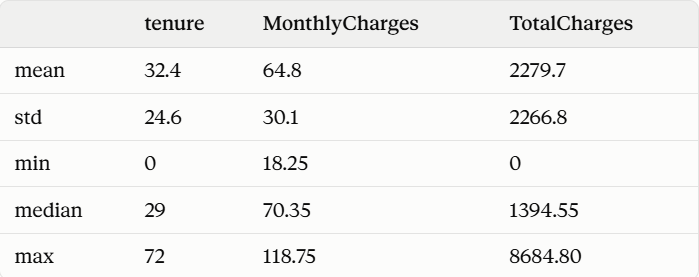

Four observations:

1. Tenure spans 0–72 months with a wide spread (std ≈ 24.6) — the customer base is a genuine mix of brand-new and long-standing customers, not clustered around one point.
2. MonthlyCharges is right-skewed toward the lower end (median 70.35 vs mean 64.76 is actually close, but min 18.25 shows a cluster of low-cost, likely phone-only customers).
3. TotalCharges has by far the largest spread relative to its scale (std nearly equal to the mean), which makes sense since it's the product of tenure × monthly rate.
4. The target is imbalanced: 73.5% No / 26.5% Yes — this needs to be flagged again in Week 5 for the modeling stage (e.g. stratified train/test split, or class weighting).

Task 9: Explore Individual Variables

Chart 1 — Target variable distribution

In [ ]:
sns.countplot(data=df, x="Churn", hue="Churn", palette=["#4C72B0","#DD8452"], legend=False)
plt.title("Distribution of Churn (Target Variable)")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

What was done: A count plot of the Churn column, the project's target variable.

Why: Every EDA of a classification problem needs to show the target's balance first, since it affects how the model will be trained and evaluated in Week 5.

What the output means: 5,174 customers (73.5%) did not churn and 1,869 (26.5%) did. The classes are imbalanced roughly 3:1, which will need to be accounted for later (e.g. stratified splitting, class weighting, or evaluating with precision/recall rather than accuracy alone).

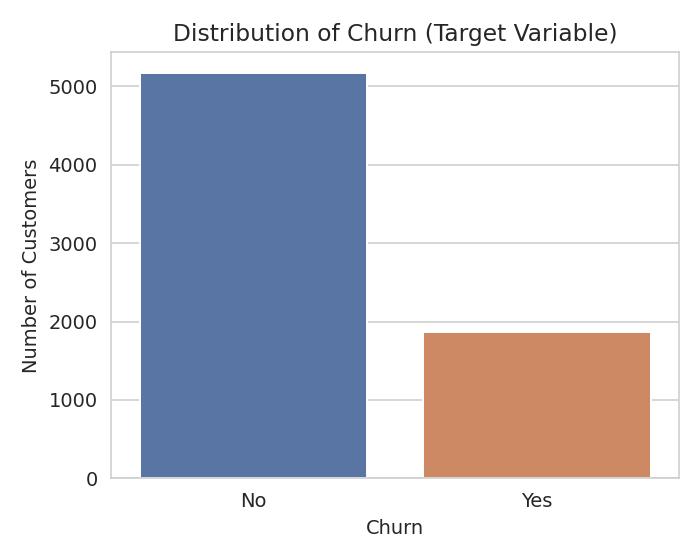

Chart 2 — Tenure distribution

In [ ]:
sns.histplot(data=df, x="tenure", kde=True, color="#4C72B0")
plt.title("Distribution of Tenure (Months)")
plt.xlabel("Tenure (months)")
plt.ylabel("Frequency")
plt.show()

What was done: A histogram with a density curve for tenure, the only numerical variable directly measuring the customer relationship.

Why: Understanding how long customers typically stay helps interpret churn later — a variable this skewed is often a strong churn signal.

What the output means: The distribution is not centered around one value — there is a large spike of customers in their first few months (0–5 months) and a second, smaller build-up near the 70–72 month mark. Very few customers sit in the middle range. This U-shape suggests two distinct populations: customers who leave early, and a loyal group who stay near the maximum observed tenure.

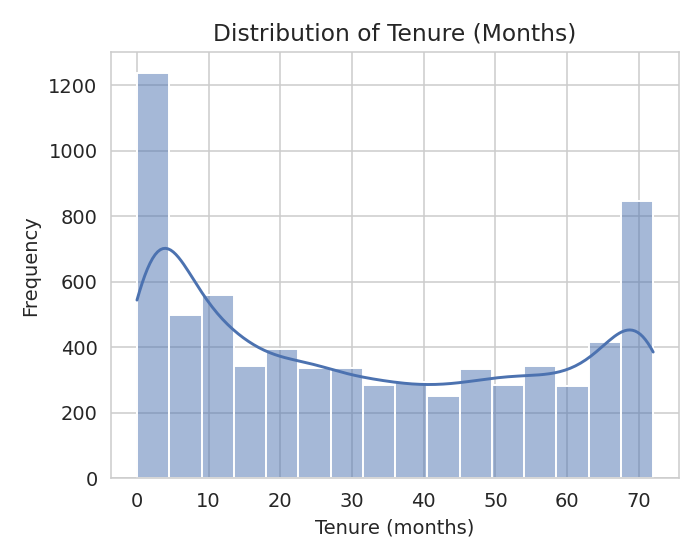

Chart 3 — Contract type distribution

In [ ]:
sns.countplot(data=df, x="Contract", hue="Contract",
              order=df["Contract"].value_counts().index,
              palette="Blues_d", legend=False)
plt.title("Distribution of Contract Type")
plt.xlabel("Contract")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

What was done: A count plot of Contract, an important categorical predictor.

Why: Contract type is one of the variables most commonly linked to churn behavior in subscription businesses, so its distribution needs to be understood before relating it to the target in Task 10.

What the output means: Month-to-month is by far the most common contract (55.0%, 3,875 customers), followed by two-year (24.1%) and one-year (20.9%). Because month-to-month customers face no penalty for leaving, this imbalance is worth carrying into Task 10, where we check whether it also corresponds to higher churn.

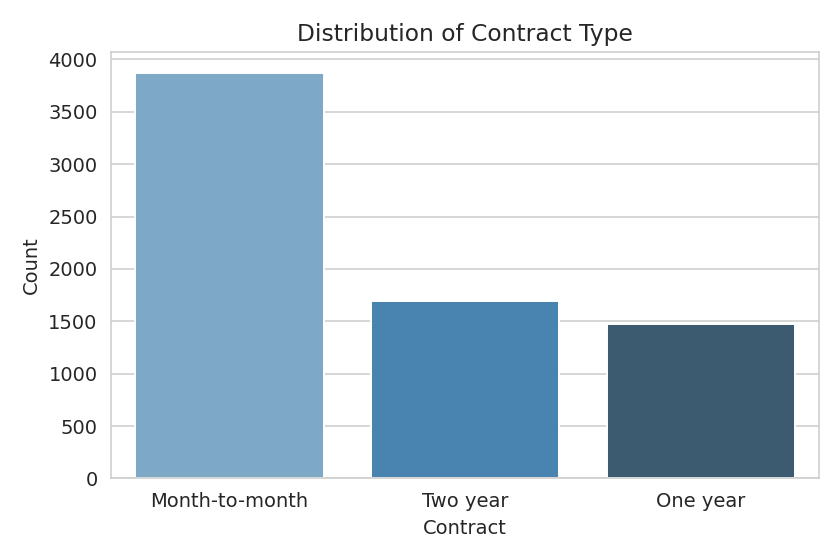

##Task 10: Explore Relationships Between Variables


Three important predictors are examined against the target: `Contract` and `PaymentMethod` (categorical) and `tenure` (numerical).

In [ ]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index").mul(100).round(1)
print("Churn rate by contract type (%)")
display(contract_churn)

In [ ]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index").mul(100).plot(
    kind="bar", stacked=False, color=["#4C72B0", "#DD8452"], figsize=(7, 4.5))
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract type")
plt.ylabel("Percentage of customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

**What the output means:** Contract type has the strongest relationship with churn of any variable examined. Month-to-month customers churn at 42.7% — more than one in every four customers leaving. One-year contracts drop this to 11.3%, and two-year contracts to 2.8%, a fifteen-fold difference from month-to-month. Since 55% of all customers are on month-to-month contracts, this group contains the large majority of churn in the dataset and is the obvious priority for the retention team.

###2. Tenure vs churn

In [ ]:
print(df.groupby("Churn")["tenure"].agg(["mean", "median", "min", "max"]).round(2))

In [ ]:
sns.boxplot(data=df, x="Churn", y="tenure", hue="Churn",
            palette=["#4C72B0", "#DD8452"], legend=False)
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.tight_layout()
plt.show()

**What the output means:** Customers who churned had been with the company for an average of 18 months against 37.6 months for those who stayed. The medians are more striking — 10 months against 38. Half of all churners leave within their first ten months. The box plot shows the churn group compressed at the low end of the tenure scale, confirming that churn risk is concentrated among newer customers. This supports focusing retention effort on the first year of a customer's relationship.

###3. Payment methid vs Churn

In [ ]:
payment_churn = pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index").mul(100).round(1)
print("Churn rate by payment method (%)")
display(payment_churn.sort_values("Yes", ascending=False))

In [ ]:
payment_churn["Yes"].sort_values().plot(kind="barh", color="#DD8452", figsize=(7, 4))
plt.title("Churn Rate by Payment Method")
plt.xlabel("Churn rate (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

**What the output means:** Electronic check customers churn at 45.3%, nearly three times the rate of the two automatic payment methods (16.7% and 15.2%). The two automatic methods behave almost identically, which suggests the distinction that matters is automatic versus manual payment rather than the specific method. A customer paying automatically has a standing arrangement that continues without action; a customer paying by electronic check makes an active decision every month, and each of those is an opportunity to stop.

**Note on interpretation:** These are associations, not causes. Moving a customer onto a two-year contract would not by itself make them loyal — customers who already intend to stay are more likely to accept a long contract in the first place. These relationships identify *where* churn concentrates, which is what the retention team needs; establishing cause would require a different kind of study.

## Task 11: Examine Numerical Correlations

The cleaned dataset contains three numerical variables: `tenure`, `MonthlyCharges` and `TotalCharges`. The target is added as a temporary 0/1 column so its relationship with each numerical variable appears in the matrix. This column is created for analysis only and is not saved back to the dataset.

In [ ]:
# Temporary numeric version of the target, for correlation only
numeric_df = df[["tenure", "MonthlyCharges", "TotalCharges"]].copy()
numeric_df["Churn_num"] = (df["Churn"] == "Yes").astype(int)

correlation = numeric_df.corr()
display(correlation.round(3))

In [ ]:
plt.figure(figsize=(6.5, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1, center=0, linewidths=2, linecolor="white")
plt.title("Correlation Matrix — Numerical Variables and Churn")
plt.tight_layout()
plt.show()

**How to read this:** Correlation runs from −1 to +1. A positive value means the two variables rise together; a negative value means one rises as the other falls. Values near 0 mean little linear relationship. The diagonal is always 1.000 because every variable correlates perfectly with itself.

`coolwarm` is the appropriate colour scale here because correlation has a meaningful midpoint at zero, with negative and positive values on either side.

**What the output means:**

**`tenure` and `TotalCharges` are strongly correlated (0.826).** This is expected rather than informative — the longer a customer stays, the more they have been billed in total. The two variables carry overlapping information, which matters for modelling in Week 5 because highly correlated predictors can make individual coefficients unstable and hard to interpret.

**`tenure` has the strongest relationship with churn (−0.352).** The sign is negative, meaning longer-tenured customers are less likely to churn. This is the strongest numerical association with the target and confirms the tenure pattern seen in Task 10.

**`MonthlyCharges` is weakly positively related to churn (0.193).** Customers paying more per month are somewhat more likely to leave, though the relationship is weak.

**`TotalCharges` is weakly negatively related to churn (−0.198).** This appears to contradict `MonthlyCharges`, but it does not: `TotalCharges` is largely a reflection of tenure, and long-tenured customers rarely churn. The negative sign is inherited from tenure rather than being an effect of total spending.

**`MonthlyCharges` and `TotalCharges` are moderately correlated (0.651)**, which is again structural — total charges accumulate from monthly charges.

**Important limitation:** correlation measures only *linear* relationships between *numerical* variables. The strongest predictors found in Task 10 — `Contract` and `PaymentMethod` — are categorical and cannot appear in this matrix at all. Contract type showed a far larger difference in churn rate (42.7% against 2.8%) than any correlation here. The correlation matrix is therefore a partial view and should be read alongside the relationship analysis in Task 10, not instead of it.

**Correlation is not causation.** A negative correlation between tenure and churn does not mean that keeping a customer longer causes loyalty; customers who were always likely to stay naturally accumulate longer tenure.

## Task 12: Summary of EDA Findings

### What are the main characteristics of the dataset?

The cleaned dataset contains 7,043 customer records described by 19 predictors, one identifier and one target variable. Each row represents one customer. The predictors fall into four groups: demographics, services subscribed to, account information and billing amounts. Three variables are numerical — `tenure` (0–72 months), `MonthlyCharges` (18.25–118.75) and `TotalCharges` (0–8,684.80) — and the remaining sixteen are categorical. After the Stage 3 cleaning the dataset contains no missing values, no duplicate records and no inconsistent category labels.

### How is the target variable distributed? Is there evidence of imbalance?

`Churn` is imbalanced. 5,174 customers (73.5%) did not churn and 1,869 (26.5%) did — roughly three non-churners for every churner. This imbalance has direct consequences for Week 5: a model predicting "No churn" for every customer would achieve 73.5% accuracy while identifying no churners at all. Accuracy alone will therefore be an inadequate measure, and recall, precision, F1 and the confusion matrix will be needed.

### Which variables show important patterns or relationships with the target?

**Finding 1 — Contract type is the strongest single predictor.** Churn is 42.7% among month-to-month customers, 11.3% on one-year contracts and 2.8% on two-year contracts. Since 55.0% of all customers are on month-to-month terms, this group contains most of the churn in the dataset.

**Finding 2 — Churn is concentrated among new customers.** Customers who churned averaged 18.0 months of tenure against 37.6 months for those who stayed, and the medians differ more sharply still: 10 months against 38. Half of all churners leave within their first ten months.

**Finding 3 — Manual payment is associated with much higher churn.** Electronic-check customers churn at 45.3%, roughly three times the rate of bank transfer (16.7%) and credit card (15.2%). The two automatic methods behave almost identically, suggesting the meaningful distinction is automatic versus manual payment rather than the specific method.

**Finding 4 — Fibre optic customers churn most.** Churn is 41.9% among fibre optic customers, 19.0% for DSL and 7.4% for customers with no internet service. Fibre is the premium product, so the highest churn occurring there is worth investigating as a possible price or service-quality issue.

**Finding 5 — Tenure is the strongest numerical correlate of churn (−0.352).** `MonthlyCharges` is weakly positive (0.193) and `TotalCharges` weakly negative (−0.198). All three are weaker than the categorical relationships above.

### What unexpected findings or limitations were identified?

The `TotalCharges` correlation with churn is negative (−0.198) while `MonthlyCharges` is positive (0.193), which looks contradictory. It is explained by the strong correlation between `TotalCharges` and `tenure` (0.826) — total charges mainly reflect how long a customer has been present, and long-tenured customers rarely leave. This is a reminder that correlated predictors cannot be interpreted in isolation.

The high correlation between `tenure` and `TotalCharges` is itself a limitation for modelling, as overlapping predictors can make individual model coefficients unstable.

The correlation matrix also covers only the three numerical variables. The strongest predictors identified — `Contract`, `PaymentMethod` and `InternetService` — are categorical and do not appear in it, so the correlation analysis gives only a partial picture of the dataset.

Finally, the dataset contains no date variable, no record of why customers left, and no customer service or satisfaction history. The analysis can therefore identify *where* churn concentrates but not *why* individual customers decided to leave.

### How do the findings help answer the project objectives?

The project's general objective is to predict customer churn so the retention team can act before customers leave. The EDA confirms that the dataset contains variables with strong, consistent relationships to churn — contract type, tenure, payment method and internet service — which are exactly the kind of information a company already holds about its active customers. This means a predictive model built on these variables is both feasible and usable in practice.

The findings also give the retention team an immediate profile to act on, independent of any model: a recently joined customer on a month-to-month contract paying by electronic check with fibre optic internet is the highest-risk combination in the dataset.

### Is the cleaned dataset ready for Machine Learning in Week 5?

Yes. The dataset contains 7,043 records with no missing values, no duplicates and correct data types. The target variable is present and binary. The predictors are relevant, show measurable relationships with the target, and are sufficient in number.

Two items must be handled during modelling rather than now. First, the categorical variables need encoding into numerical form before they can be used by scikit-learn models. Second, the 73.5% / 26.5% class imbalance must be addressed, either through class weighting or through resampling, and evaluation must go beyond accuracy.

With those two steps, the dataset is ready for model development.

#WEEK 5: MODEL TRAINING

## Task 1: Define the Prediction Problem

### Project problem

Telecommunication companies operate on subscription services where customers are free to cancel at any time. The retention and marketing team only becomes aware of churn after a customer has already left, and has no reliable way of ranking active customers by their risk of leaving. Retention offers are therefore given late, or given to customers who were never going to leave.

### Project objectives

**General objective:** To develop a machine learning model that predicts customer churn in a telecommunications company using customer demographic, service and billing information.

**Specific objectives:**

1. To examine and understand the structure, variables and quality of the Telco customer churn dataset. *(completed in Stage 2)*
2. To clean and prepare the dataset for machine learning modelling. *(completed in Stage 3)*
3. To build and evaluate a classification model that predicts whether a customer will churn. *(this stage)*

### Target variable

The target variable is **`Churn`**, which records whether a customer discontinued the company's services. It takes two values, Yes and No, and is distributed 73.5% No and 26.5% Yes.

### Predictor variables

The 19 predictors identified in Stage 2 and retained in the cleaned dataset:

| Group | Variables |
|---|---|
| Customer demographics | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Services subscribed to | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Account information | `tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod` |
| Billing amounts | `MonthlyCharges`, `TotalCharges` |

`customerID` is excluded from the predictors. It is a unique label with no predictive value — every value appears exactly once, so a model would attempt to memorise individual customers rather than learn patterns.

### Type of problem: classification

This is a **supervised binary classification** problem.

It is **supervised** because every record in the dataset carries a known outcome in the `Churn` column, so the model learns from labelled examples.

It is **classification rather than regression** because the target is a category with two possible values (Yes / No), not a continuous quantity. Regression predicts a number such as a price or a temperature, where the distance between values is meaningful. "Yes" and "No" have no numerical distance between them — the model's task is to assign each customer to one of two groups, not to estimate a magnitude.

It is **binary** rather than multi-class because there are exactly two outcome classes.

This choice determines everything that follows: classification models (Logistic Regression, Decision Tree, Random Forest) and classification metrics (accuracy, precision, recall, F1, confusion matrix) rather than regression models and error-based measures such as RMSE or R².

In [ ]:
import pandas as pd

df_clean = pd.read_csv("cleaned_project_dataset.csv")

print("dataset shape: ", df_clean.shape)
print()
print("target variable - Churn")
print(df_clean["Churn"].value_counts())
print()
print(df_clean["Churn"].value_counts(normalize=True).mul(100).round(1))
print()
print("number of distinct target values: ", df_clean["Churn"].nunique(), "-> binary classification")

**What was done:** The cleaned dataset from Stage 3 was loaded and the target variable inspected.

**Why:** Confirming the number of distinct target values is what establishes the problem type. Two categories means binary classification.

**What the output means:** The dataset contains 7,043 records and 21 columns. `Churn` has exactly two values — 5,174 "No" (73.5%) and 1,869 "Yes" (26.5%). The target is imbalanced, with roughly three non-churners for every churner. This imbalance is recorded here because it directly shapes the modelling choices in Task 4 and the evaluation measures in Task 5: a model that predicted "No" for every customer would score 73.5% accuracy while identifying no churners at all.

##Task 2: Prepare the data for modeling

In [ ]:
import pandas as pd

df_clean = pd.read_csv("cleaned_project_dataset.csv")

# Separate predictors from target
y = (df_clean["Churn"] == "Yes").astype(int)
X = df_clean.drop(columns=["customerID", "Churn"])

print("Predictors:", X.shape[1], "| Target values:", y.unique())
print("Missing values remaining:", X.isnull().sum().sum())

In [ ]:
# Encode categorical variables
X = pd.get_dummies(X, drop_first=True)

print("Columns after encoding:", X.shape[1])
print(X.columns.tolist())

**What was done:** The identifier and target were removed from the predictors, `Churn` was converted to 1 (Yes) / 0 (No), and the categorical variables were one-hot encoded.

**Why:** Scikit-learn models require numeric input. `get_dummies` creates one binary column per category. `drop_first=True` omits one category per variable as the reference level — keeping all of them would make the columns perfectly redundant, which destabilises logistic regression coefficients.

**Why `customerID` was dropped:** Every value is unique, so it carries no pattern to learn. Left in, it would be encoded into thousands of columns and the model would memorise individual customers.

**What the output means:** 19 predictors expand to 23 encoded columns, all numeric, with zero missing values — confirming the Stage 3 cleaning carried through. Scaling is applied after the split in Task 3, not here.

##Task 3: spliting the dataset

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Step 1: hold out 15% as the test set
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y)

# Step 2: split the remaining 85% into 60% train and 25% validation
val_ratio = 0.25 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=val_ratio, random_state=42, stratify=y_temp)

n = len(X)
for name, s in [("Training", X_train), ("Validation", X_val), ("Test", X_test)]:
    print(f"{name:12} {len(s):5}  ({len(s)/n*100:.1f}%)")

print("\nChurn rate preserved:")
print(f"  Training  : {y_train.mean()*100:.2f}%")
print(f"  Validation: {y_val.mean()*100:.2f}%")
print(f"  Test      : {y_test.mean()*100:.2f}%")

In [ ]:
# Scale the numerical variables — fitted on training data only
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler().fit(X_train[num_cols])

X_train_s, X_val_s, X_test_s = X_train.copy(), X_val.copy(), X_test.copy()
X_train_s[num_cols] = scaler.transform(X_train[num_cols])
X_val_s[num_cols]   = scaler.transform(X_val[num_cols])
X_test_s[num_cols]  = scaler.transform(X_test[num_cols])

print(X_train_s[num_cols].describe().round(2))

**What was done:** The data was split into three sets and the numerical variables standardised.

**Why three sets:** The assignment requires training and testing sets. A separate validation set was added so that model comparison and final evaluation use different data. Models are compared on the validation set; the test set is used once, after the best model is chosen, so its score is an honest estimate of performance on unseen customers.

**Why the ratio is 0.294 and not 0.25:** `train_test_split` divides whatever it is given. After removing 15% for testing, 85% remains, so obtaining 25% of the original data requires 0.25 / 0.85 = 0.294 of that remainder.

**Why `stratify`:** The target is imbalanced at 26.5% churn. Stratifying preserves that proportion in all three sets, so no set is accidentally easier or harder than another.

**Why the scaler is fitted on training data only:** Fitting on the full dataset would let information from the validation and test sets influence the training process — data leakage. The scaler learns the mean and standard deviation from the training set alone and applies them to the other two.

**What the output means:** 4,225 training / 1,761 validation / 1,057 test rows, with churn at 26.56%, 26.52% and 26.49% — essentially identical. The scaled training columns have mean ≈ 0 and standard deviation ≈ 1.

| Set | Rows | Purpose |
|---|---|---|
| Training (60%) | 4,225 | The models learn from this only |
| Validation (25%) | 1,761 | Compare models and select the best |
| Test (15%) | 1,057 | Final performance estimate, used once |

##Task 4: Train the models

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

#model 1: Logistic Regression
log_reg = LogisticRegression(max_iter=2000, class_weight = "balanced", random_state =42)
log_reg.fit(X_train_s, y_train)

#model 2: decision tree
dec_tree = DecisionTreeClassifier(max_depth = 5, class_weight="balanced", random_state = 42)
dec_tree.fit(X_train, y_train)

print("Both models trained on", len(X_train), "records")

In [ ]:
#generate predictions on the validation set
y_pred_lr = log_reg.predict(X_val_s)
y_pred_dt = dec_tree.predict(X_val)

#predicted probabilities, needed for ROC-AUC
y_prob_lr = log_reg.predict_proba(X_val_s)[:, 1]
y_prob_dt = dec_tree.predict_proba(X_val)[:, 1]

print("Logistic Regression - predicted churners:", y_pred_lr.sum(), "of", len(y_val))
print("Decision Tree       - predicted churners:", y_pred_dt.sum(), "of", len(y_val))
print("actual churners in validation set: ", y_val.sum())

In [ ]:
#An unrestricted tree, for comparison only
dt_full = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
from sklearn.metrics import roc_auc_score
print("Unlimited tree ROC-AUC:", round(roc_auc_score(y_val, dt_full.predict_proba(X_val)[:,1]),3))
print("Depth-5 tree ROC-AUC: ", round(roc_auc_score(y_val, y_prob_dt), 3))
print("Unlimited tree depth:", dt_full.get_depth())

**Why Logistic Regression was selected:** It is the standard baseline for binary classification. It produces a probability of churn for each customer, which lets the retention team rank customers by risk rather than receive only a Yes/No label. Its coefficients are directly interpretable — each one shows both the size and the direction of a variable's effect — which supports Task 6. It is also very small when saved, which matters for the application integration in the next stage.

**Why a Decision Tree was selected:** It works in a completely different way, splitting the data into groups through a series of yes/no questions rather than fitting a single equation. This makes it a genuine point of comparison rather than a variation of the same approach. It handles non-linear relationships and interactions between variables that logistic regression cannot capture, and its structure can be read directly as decision rules.

**Why `class_weight="balanced"` on both:** The target is 73.5% / 26.5%. Without weighting, both models minimise total error by favouring the majority class and under-predicting churn. Balancing makes each class contribute equally to the training objective, so the models are penalised properly for missing a churner. Applying it to both keeps the comparison fair — the difference measured is between the two model types, not between two weighting schemes.

**Why the tree depth was limited to 5:** An unrestricted tree grows until it separates almost every training record, memorising the training data. Its ROC-AUC on validation data is 0.690 against 0.827 for the depth-5 tree, despite fitting the training set almost perfectly. Limiting the depth is what makes the tree generalise.

**What the output means:** Logistic Regression flags 727 of 1,761 validation customers as likely churners; the Decision Tree flags fewer. The actual number of churners is 467. Both over-predict, which is the expected consequence of balancing — and the desirable direction here, since a missed churner costs more than an unnecessary retention offer.

##task 5: Evaluateand compare the models

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

def evaluate(name, y_true, y_pred, y_prob):
    return {
        "Model":     name,
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall":    recall_score(y_true, y_pred),
        "F1 score":  f1_score(y_true, y_pred),
        "ROC-AUC":   roc_auc_score(y_true, y_prob),
    }

results = pd.DataFrame([
    evaluate("Logistic Regression (balanced)", y_val, y_pred_lr, y_prob_lr),
    evaluate("Decision Tree, depth 5 (balanced)", y_val, y_pred_dt, y_prob_dt),
]).round(3)

print("MODEL COMPARISON — validation set (1,761 customers)")
print(results.to_string(index=False))

In [ ]:
# Confusion matrices
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = ["No churn", "Churn"]

matrices = {
    "Logistic Regression (balanced)":    confusion_matrix(y_val, y_pred_lr),
    "Decision Tree, depth 5 (balanced)": confusion_matrix(y_val, y_pred_dt),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

for ax, (name, cm) in zip(axes, matrices.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax,
                linewidths=2, linecolor="white", annot_kws={"size": 14})
    ax.set_title(name, fontsize=11, pad=12)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Confusion Matrices — Validation Set (1,761 customers)", fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
print("Logistic Regression\n", classification_report(y_val, y_pred_lr,
                                target_names=["No churn", "Churn"]))
print("Decision Tree\n", classification_report(y_val, y_pred_dt,
                                target_names=["No churn", "Churn"]))

**What was done:** Both models were evaluated on the validation set using five measures and a confusion matrix each.

**Why these measures:** The assignment states that accuracy alone must not be relied on when the target is imbalanced. With 73.5% of customers not churning, a model that predicted "No" for everyone would score 73.5% accuracy while identifying no churners at all — higher than either model here, and completely useless. Precision, recall, F1 and ROC-AUC are therefore reported alongside accuracy.

### What each measure means for this project

| Measure | Meaning in this project |
|---|---|
| Accuracy | Share of all customers classified correctly |
| Precision | Of the customers flagged as churners, how many actually churned |
| Recall | Of the customers who actually churned, how many the model found |
| F1 score | Balance between precision and recall |
| ROC-AUC | How well the model separates churners from non-churners across all thresholds |

### Confusion matrices — validation set

**Logistic Regression (balanced)**

|  | Predicted: No churn | Predicted: Churn |
|---|---|---|
| **Actual: No churn** | 937 | 357 |
| **Actual: Churn** | **97** | **370** |

**Decision Tree, depth 5 (balanced)**

|  | Predicted: No churn | Predicted: Churn |
|---|---|---|
| **Actual: No churn** | 966 | 328 |
| **Actual: Churn** | **121** | **346** |

**What the output means:** The two models are almost identical on accuracy (0.742 vs 0.745) and precision (0.509 vs 0.513), so those measures do not separate them. The differences appear in recall and ROC-AUC.

Logistic Regression finds **370 of 467** churners (79.2%) and misses 97. The Decision Tree finds **346** and misses 121 — **24 more churners missed**. In exchange, the Decision Tree raises 29 fewer false alarms (328 against 357).

That is the trade-off, and it is not symmetrical for this project. A missed churner is a customer who leaves without any retention offer being made — lost revenue, and the exact failure the project exists to prevent. A false alarm is a retention offer sent to a customer who would have stayed — a wasted discount. Missing 24 additional churners to avoid 29 unnecessary offers is a poor exchange for the retention team.

Logistic Regression also has the higher ROC-AUC (0.842 against 0.827), meaning it ranks customers by churn risk more reliably regardless of where the decision threshold is set. Since the retention team's intended use is a ranked list of at-risk customers, this measure matters directly.

##Task 6: Select and interpret the best model

In [ ]:
# Final evaluation of the selected model on the held-out test set
y_pred_test = log_reg.predict(X_test_s)
y_prob_test = log_reg.predict_proba(X_test_s)[:, 1]

print("FINAL TEST RESULTS — Logistic Regression (balanced)")
print("Test customers:", len(y_test))
print()
print(f"Accuracy : {accuracy_score(y_test, y_pred_test):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_test):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred_test):.3f}")
print(f"F1 score : {f1_score(y_test, y_pred_test):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_test):.3f}")
print()
sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt="d",
            cmap="Blues", cbar=False,
            xticklabels=["No churn", "Churn"], yticklabels=["No churn", "Churn"],
            linewidths=2, linecolor="white", annot_kws={"size": 14})
plt.title("Confusion Matrix — Test Set (1,057 customers)")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

**Why this model was selected:** The comparison in Task 5 showed the two models were close on accuracy (0.742 vs 0.745) and precision (0.509 vs 0.513). They differed on the measures that matter for this project. Logistic Regression missed 97 churners against the Decision Tree's 121, and achieved a higher ROC-AUC (0.842 vs 0.827), meaning it ranks customers by churn risk more reliably. Since the project's purpose is to give the retention team a ranked list of at-risk customers before they leave, both of these favour Logistic Regression.

The difference in total errors is small — Logistic Regression makes 24 fewer misses but 29 more false alarms. The selection therefore rests on the *cost* of each error rather than the count. A missed churner is a customer lost permanently along with their future revenue; a false alarm is a retention offer given to a customer who would have stayed. These are not equivalent, so reducing misses is worth accepting more false alarms.

**Test set performance:** On the 1,057 customers the model had never seen, it achieved recall of 0.800 and ROC-AUC of 0.849 — slightly better than on the validation set. This confirms the model was not over-fitted during selection.

The model correctly identified **224 of 280** actual churners and missed 56. It raised 219 false alarms out of 777 customers who stayed.

In [ ]:
# Which variables matter most
import numpy as np

coefficients = pd.DataFrame({
    "Variable": X_train.columns,
    "Coefficient": log_reg.coef_[0]
})
coefficients["Effect"] = np.where(coefficients["Coefficient"] > 0,
                                  "Increases churn risk", "Reduces churn risk")
coefficients["Strength"] = coefficients["Coefficient"].abs()

top = coefficients.sort_values("Strength", ascending=False).head(12)
display(top[["Variable", "Coefficient", "Effect"]].round(3).reset_index(drop=True))

## Task 7: Discuss Limitations and Save the Best Model

### Limitations of the dataset

The dataset contains no date or time variable, so it is not possible to analyse how churn has changed over time or to test the model on a later period of customers. It records no reason for leaving, no customer service or complaint history, and no measure of customer satisfaction, which means the model can identify who is at risk but not why any individual customer decided to leave. There is also no usage data such as call minutes or data consumption, no geographic location, and no information about competitor pricing or offers.

The dataset is a static snapshot of 7,043 customers from a fictional company published by IBM for analytics practice. Results obtained from it should not be assumed to transfer directly to a real telecommunications company without retraining on that company's own data.

### Limitations of the analysis

The target is imbalanced at 73.5% to 26.5%. This was addressed using `class_weight="balanced"`, but the model still has far fewer churn examples to learn from than non-churn examples. Model hyperparameters were not tuned systematically — the tree depth was chosen by comparing two options rather than by a full search, and no cross-validation was performed, so the reported scores depend to some extent on this particular random split. Only two model types were compared; other approaches such as Random Forest or gradient boosting were not explored.

### Limitations of the selected model

Precision is 0.506 on the test set, meaning roughly half the customers flagged as churners would not actually have left. Of 443 customers flagged, 219 were false alarms. The retention team should expect about half of its offers to go to customers who were staying anyway.

The model also still misses 56 of 280 churners — 20% of customers who leave receive no warning.

Logistic regression assumes an additive relationship between the predictors and the log-odds of churn. It cannot capture interactions between variables unless those are added explicitly, so a combination such as "fibre optic customers specifically on month-to-month contracts" is not modelled as a distinct effect.

Finally, the coefficients show association rather than causation. They identify which customer characteristics accompany churn; they do not establish that changing a characteristic would change the outcome.

### Does the model adequately address the project problem?

Yes, for its intended purpose. The project set out to give the retention team a way to identify high-risk customers before they leave, replacing a reactive process that only recognised churn after the fact. The model identifies 80% of customers who go on to churn and ranks all customers by risk with a ROC-AUC of 0.849, which is a substantial improvement over having no early warning at all.

It is suitable for prioritising retention effort, not for making automated decisions about individual customers. Given a precision of around 0.5, the output should be treated as a ranked list for the team to work through rather than a final verdict, and a human should remain involved in deciding what offer each customer receives.

In [ ]:
#saving the model
import joblib

# The scaler must be saved with the model - the application will need to
# apply the same transformation to new customer data
joblib.dump(log_reg, "churn_model.pkl")
joblib.dump(scaler, "churn_scaler.pkl")
joblib.dump(list(X_train.columns), "churn_features.pkl")

print("Saved:")
print("  churn_model.pkl    - the trained Logistic Regression model")
print("  churn_scaler.pkl   - the fitted StandardScaler")
print("  churn_features.pkl - the 23 encoded column names, in order")

In [ ]:
import joblib

# The scaler must be saved with the model - the application will need to
# apply the same transformation to new customer data
joblib.dump(log_reg, "churn_model.pkl")
joblib.dump(scaler, "churn_scaler.pkl")
joblib.dump(list(X_train.columns), "churn_features.pkl")

print("Saved:")
print("  churn_model.pkl    - the trained Logistic Regression model")
print("  churn_scaler.pkl   - the fitted StandardScaler")
print("  churn_features.pkl - the 23 encoded column names, in order")

**What was done:** The trained model, the fitted scaler and the list of feature names were saved to disk using `joblib`, and the saved model was reloaded and verified to produce identical predictions.

**Why all three files are needed:** The model alone is not enough. New customer data arriving in the application will be raw — unscaled and unencoded. The application must apply the *same* scaling the model was trained with, which requires the fitted scaler, and it must present the columns in the *same order* with the same encoded names, which requires the feature list. Saving only `churn_model.pkl` would produce a model that runs but returns meaningless predictions.

**What the output means:** The reloaded model reproduces the original predictions exactly, confirming the saved file is valid and ready for the application development in the next stage.